In [1]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║            НАСТРОЙКИ — МЕНЯТЬ ТОЛЬКО В ЭТОЙ ЯЧЕЙКЕ              ║
# ╚══════════════════════════════════════════════════════════════════╝
DATA_DIR        = 'data'
DATE_FROM       = None
DATE_TO         = None

TOP_N           = 15
SLOW_DAYS       = 21
COVER_DAYS      = 4
COVER_LOOKBACK  = 28
GLOBAL_MARKUP   = 2.0
MARGIN_TARGET   = 40

MIN_SUPPORT     = 0.003
MIN_PAIR_COUNT  = 5
EXCLUDE_FROM_BASKET = ['Услуги флориста']

FORECAST_DAYS   = 14

WRITEOFF_SPIKE_KOEF = 2.0
RETURN_RATE_ALERT   = 5.0

EXPORT_XLSX     = True
OUTPUT_DIR      = 'output'

print('✅ Настройки загружены')

✅ Настройки загружены


In [2]:
import os, re, warnings
from pathlib import Path
from itertools import combinations
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches

warnings.filterwarnings('ignore')
try:
    display
except NameError:
    display = print

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': '#F8F9FA', 'axes.facecolor': '#F8F9FA',
    'axes.grid': True, 'grid.alpha': .4, 'grid.linestyle': '--',
})

PALETTE = ['#2563EB','#10B981','#F59E0B','#EF4444','#8B5CF6','#EC4899',
           '#06B6D4','#84CC16','#F97316','#6366F1','#14B8A6','#FBBF24']
ABC_COLORS = {'A':'#10B981','B':'#F59E0B','C':'#EF4444'}
DAYS_RU = ['Пн','Вт','Ср','Чт','Пт','Сб','Вс']

def rub(v):    return '—' if pd.isna(v) else f'{v:,.0f} ₽'.replace(',', ' ')
def num_fmt(v):return '—' if pd.isna(v) else f'{v:,.0f}'.replace(',', ' ')
def pct(v):    return '—' if pd.isna(v) else f'{v:.1f}%'
def fmt_rub_axis(x, pos=None):
    if abs(x) >= 1_000_000: return f'{x/1e6:.1f}М'
    if abs(x) >= 1_000:     return f'{x/1e3:.0f}К'
    return f'{x:.0f}'

def norm_name(s):
    return re.sub(r'[\s_]+',' ',str(s).lower().replace('ё','е')).strip()

def to_num(s):
    if not isinstance(s, pd.Series):
        s = pd.Series(s)
    s = s.astype(str).str.replace(r'[^0-9,.\-]','',regex=True).str.replace(',', '.', regex=False)
    return pd.to_numeric(s, errors='coerce')

def pick_col(df, *parts):
    for c in df.columns:
        n = norm_name(c)
        if all(p in n for p in parts):
            return c
    return None

def find_file(*keywords, ext=('.csv','.xls','.xlsx')):
    if not os.path.isdir(DATA_DIR):
        raise FileNotFoundError(f'Нет папки «{DATA_DIR}».')
    for f in sorted(os.listdir(DATA_DIR)):
        fl = norm_name(f)
        if f.lower().endswith(ext) and not f.startswith('~'):
            for kw in keywords:
                if norm_name(kw) in fl:
                    return os.path.join(DATA_DIR, f)
    return None

def read_csv_smart(path, **kw):
    last = None
    for enc in ('utf-8-sig','cp1251','utf-8'):
        try:
            return pd.read_csv(path, sep=';', encoding=enc, dtype=str, **kw)
        except UnicodeDecodeError as e:
            last = e
    raise RuntimeError(f'Не читается {path}: {last}')

def read_table_any(path, header=None, **kw):
    p = Path(path); suf = p.suffix.lower()
    if suf == '.xls':
        return pd.read_excel(p, header=header, dtype=str, engine='xlrd', **kw)
    if suf == '.xlsx':
        return pd.read_excel(p, header=header, dtype=str, engine='openpyxl', **kw)
    return read_csv_smart(p, header=header, **kw)

CATEGORY_RULES = [
    ('Услуги флориста',       r'флор\s*услуг|услуга'),
    ('Упаковка и аксессуары', r'короб|конверт|открытк|пакет|пакт|сумк|кашпо|оазис|декоратив|'
                              r'кризал|грунт|подкормк|лент|ваза|топпер|сетка|плёнк|крафт|шар|свеч'),
    ('Горшечные растения',    r'\d+\s*/\s*\d+|фаленопсис|антуриум|шефлер|спатифилиум|сансивиер|'
                              r'цимбидиум|шлюмбергер|эхиверия|инжир|азалия|ало[еэ]|агава|'
                              r'адениум|аглаонема|агапантус|агератум|акалия|алиум'),
    ('Розы',                  r'(^|\s)роз[аы]($|\s|[,/])|кустов'),
    ('Хризантемы',            r'хризантем|сантини'),
    ('Зелень и наполнители',  r'эвкалипт|папортник|папоротник|аспидистр|рускус|писташ|лист дуба|'
                              r'гипсофил|лимониум|грин трик|скимия|краспедия|танацетум|брасика|'
                              r'молочай|салал|вакс|гиперек|эрингиум|кермек'),
]
def categorize(name):
    n = str(name).lower()
    for cat, pat in CATEGORY_RULES:
        if re.search(pat, n):
            return cat
    return 'Прочая срезка'

def barh_labels(ax, labels, values, colors, fmt=rub, pad=.01):
    labels, values = list(labels), list(values)
    ax.barh(labels, values, color=colors)
    top = max(values) if len(values) else 1
    for i, v in enumerate(values):
        ax.text(v + top*pad, i, fmt(v), va='center', fontsize=8.5)
    ax.set_xlim(0, top*1.28 if top > 0 else 1)

print('✅ Библиотеки и функции готовы')

✅ Библиотеки и функции готовы


In [3]:
def load_sales_prices(path):
    raw = read_table_any(path)
    if isinstance(raw.columns[0], str):
        hdr = pd.DataFrame([raw.columns]); raw = pd.concat([hdr, raw], ignore_index=True)
    raw = raw.dropna(how='all')
    raw.columns = list(range(raw.shape[1]))

    hdr_idx = None
    for i in range(min(8, len(raw))):
        row = ' '.join(map(str, raw.iloc[i].values)).lower()
        if ('товар' in row and 'кол' in row) or 'наименован' in row:
            hdr_idx = i; break

    cols_map = {}
    if hdr_idx is not None:
        for j, v in raw.iloc[hdr_idx].items():
            s = norm_name(v)
            if s: cols_map[j] = s
        data = raw.iloc[hdr_idx+1:].reset_index(drop=True)
    else:
        data = raw

    def colid(*parts):
        for j, s in cols_map.items():
            if all(p in s for p in parts): return j
        return None

    jc    = colid('товар') or colid('наименован') or colid('услуг')
    jq    = colid('кол')
    jrev  = colid('выручка','сумма') or colid('сумма')
    jprice= colid('выручка','цена')  or colid('цена')
    jcost = colid('себестоим','сумма') or colid('себестоим')

    name_series = data[jc] if jc is not None else pd.Series(index=data.index, dtype=object)
    if jc is not None and name_series.isna().mean() > 0.5 and jc > 0:
        alt = data[jc-1]
        if alt.notna().mean() > 0.5:
            name_series = alt

    out = pd.DataFrame({
        'Товар':                name_series.astype(str).str.replace(r'\s+', ' ', regex=True).str.strip(),
        'Кол-во':               to_num(data[jq])    if jq    is not None else np.nan,
        'Выручка':              to_num(data[jrev])  if jrev  is not None else np.nan,
        'Цена продажи':         to_num(data[jprice])if jprice is not None else np.nan,
        'Себестоимость, сумма': to_num(data[jcost]) if jcost is not None else np.nan,
    })
    out = out[out['Товар'].str.len() > 2]
    out = out[~out['Товар'].str.lower().str.contains('товар/услуг|наименован|итого')]
    out = out.dropna(subset=['Кол-во'])
    out = out.groupby('Товар', as_index=False).sum(numeric_only=True)
    mask = out['Цена продажи'].isna()
    out.loc[mask, 'Цена продажи'] = np.where(
        out.loc[mask, 'Кол-во'] > 0,
        out.loc[mask, 'Выручка'] / out.loc[mask, 'Кол-во'], np.nan)
    out = out[out['Цена продажи'].notna() & (out['Цена продажи'] > 0)].copy()
    out['key'] = out['Товар'].map(norm_name)
    return out

path_sales = find_file('продаж')
if path_sales is None:
    print(f'⚠️ «Продажи» НЕ найден → цена продажи = себест. ×{GLOBAL_MARKUP:.2f}')
    sales_agg = pd.DataFrame(columns=['key','Товар','Кол-во','Выручка','Цена продажи'])
else:
    sales_agg = load_sales_prices(path_sales)
    print(f'✅ {os.path.basename(path_sales)}: {len(sales_agg)} товаров, '
          f'выручка ≈ {rub(sales_agg["Выручка"].sum())}')

✅ Продажи.csv: 65 товаров, выручка ≈ 452 050 ₽


In [4]:
path_mv = find_file('движение')
if path_mv is None:
    raise FileNotFoundError('В data/ нет «Движение товаров». Скачай: Склад → Движение товаров → xls.')

mv = read_table_any(path_mv)
if isinstance(mv.columns[0], str):
    mv = mv.loc[:, ~mv.columns.str.startswith('Unnamed')]
mv.columns = list(range(mv.shape[1]))

starts = mv.index[mv[0].astype(str).str.contains('Наименован', case=False, na=False)]
start  = (starts[0] + 2) if len(starts) else 2
mv     = mv.iloc[start:].reset_index(drop=True)

is_item = mv[0].notna() & (mv[0].astype(str).str.strip() != '')
is_wh   = mv[1].notna() & (mv[1].astype(str).str.strip() != '') & ~is_item
is_doc  = mv[2].notna() & (mv[2].astype(str).str.strip() != '') & ~is_item & ~is_wh

mv['item_id']  = is_item.cumsum()
mv['item_raw'] = mv[0].ffill()
mv['wh']       = mv.groupby('item_id')[1].transform(
    lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan)

UNIT_RE = r',\s*(?:шт|кг|л|м|г|уп|компл|пара|рул|см)\.?\s*$'
def clean_item(s):
    return re.sub(UNIT_RE, '', str(s).strip(), flags=re.IGNORECASE).strip()

# ─── Итоги по товарам ─────────────────────────────────────────────────
hdr = mv[is_item]
stock = pd.DataFrame({
    'Товар':            hdr[0].map(clean_item),
    'Нач. остаток':     to_num(hdr[4]).fillna(0),
    'Приход, шт':       to_num(hdr[7]).fillna(0),
    'Приход, ₽':        to_num(hdr[9]).fillna(0),
    'Расход, шт':       to_num(hdr[10]).fillna(0),
    'Расход (себест.)': to_num(hdr[12]).fillna(0),
    'Кон. остаток':     to_num(hdr[13]).fillna(0),
    'Остаток, ₽':       to_num(hdr[15]).fillna(0),
}).reset_index(drop=True)
stock['key'] = stock['Товар'].map(norm_name)
stock = stock.groupby('key', as_index=False).agg({
    'Товар':'first','Нач. остаток':'sum','Приход, шт':'sum','Приход, ₽':'sum',
    'Расход, шт':'sum','Расход (себест.)':'sum','Кон. остаток':'sum','Остаток, ₽':'sum'})
stock['Категория'] = stock['Товар'].map(categorize)

# ─── Все документы ────────────────────────────────────────────────────
DOC_RE = re.compile(
    r'^(?P<тип>[^№]+?)\s*№\s*(?P<номер>\S+)\s+от\s+'
    r'(?P<дата>\d{2}\.\d{2}\.\d{4})(?:\s+(?P<время>\d{1,2}:\d{2}))?')
dc      = mv[is_doc].copy()
doc_txt = dc[2].astype(str).str.replace('\xa0',' ').str.strip()
info    = doc_txt.str.extract(DOC_RE)
parsed  = info['тип'].notna()
print(f'Документов: {len(dc)}, распознано: {int(parsed.sum())}, не распознано: {int((~parsed).sum())}')

docs = pd.DataFrame({
    'Тип':    np.where(parsed, info['тип'].str.strip(), doc_txt.str.slice(0,40)),
    'Номер':  np.where(parsed, info['номер'], ''),
    'Дата':   pd.to_datetime(np.where(parsed, info['дата'], ''), format='%d.%m.%Y', errors='coerce'),
    'Час':    pd.to_numeric(info['время'].str.split(':').str[0], errors='coerce'),
    'Товар':  dc['item_raw'].map(clean_item).values,
    'Склад':  dc['wh'].fillna('Основной склад').values,
    'Приход, шт': to_num(dc[7]).fillna(0).values,
    'Приход, ₽':  to_num(dc[9]).fillna(0).values,
    'Расход, шт': to_num(dc[10]).fillna(0).values,
    'Расход (себест.)': to_num(dc[12]).fillna(0).values,
})
docs['key']              = docs['Товар'].map(norm_name)
docs['Тип_norm']         = docs['Тип'].str.lower()
docs['Это_чек']          = docs['Тип_norm'].str.startswith('чек') & ~docs['Тип_norm'].str.contains('возврат')
docs['Это_возврат']      = docs['Тип_norm'].str.contains('возврат')
docs['Это_списание']     = docs['Тип_norm'].str.contains('списан')
docs['Это_поступление']  = docs['Тип_norm'].str.contains('поступлен')

print('Типы документов:', dict(docs['Тип'].value_counts().head(8)))

# ─── Таблица чеков ────────────────────────────────────────────────────
ch = docs[docs['Это_чек'] | docs['Это_возврат']].copy()
lines = pd.DataFrame({
    'check_key':     ch['Номер'].values,
    'Дата':          ch['Дата'].values,
    'Час':           ch['Час'].values,
    'Товар':         ch['Товар'].values,
    'Склад':         ch['Склад'].values,
    'Возврат':       ch['Это_возврат'].values,
    'Кол-во':        np.where(ch['Это_возврат'], -ch['Приход, шт'], ch['Расход, шт']),
    'Себестоимость': np.where(ch['Это_возврат'], -ch['Приход, ₽'],  ch['Расход (себест.)']),
})
lines['key'] = lines['Товар'].map(norm_name)
lines = lines.merge(sales_agg[['key','Цена продажи']], on='key', how='left')
lines['Цена известна'] = lines['Цена продажи'].notna()

uc = np.where(lines['Кол-во'].abs() > 0,
              lines['Себестоимость'] / lines['Кол-во'].replace(0, np.nan), np.nan)
lines['Цена продажи'] = lines['Цена продажи'].fillna(
    pd.Series(uc, index=lines.index).fillna(0) * GLOBAL_MARKUP)
lines['Выручка']   = lines['Кол-во'] * lines['Цена продажи']
lines['Маржа']     = lines['Выручка'] - lines['Себестоимость']
lines['Категория'] = lines['Товар'].map(categorize)

print(f'✅ Позиций: {num_fmt(len(lines))} | Чеков: {num_fmt(lines["check_key"].nunique())} | '
      f'Товаров в остатках: {len(stock)}')
print(f'   Период: {lines["Дата"].min():%d.%m.%Y} — {lines["Дата"].max():%d.%m.%Y}')
print(f'   Цена продажи известна для {lines["Цена известна"].mean()*100:.1f}% позиций')

Документов: 551, распознано: 551, не распознано: 0
Типы документов: {'Чек': np.int64(551)}
✅ Позиций: 551 | Чеков: 260 | Товаров в остатках: 478
   Период: 01.10.2026 — 15.10.2026
   Цена продажи известна для 78.0% позиций


In [5]:
extra = {}

# ─── Списания ─────────────────────────────────────────────────────────
p = find_file('списан')
if p:
    df_out = read_table_any(p)
    if isinstance(df_out.columns[0], str):
        hdr = pd.DataFrame([df_out.columns]); df_out = pd.concat([hdr, df_out], ignore_index=True)
    df_out.columns = [str(c).strip() for c in df_out.columns]

    c_date = pick_col(df_out, 'дата') or pick_col(df_out, 'документ')
    c_sum  = (pick_col(df_out, 'итого') or pick_col(df_out, 'сумма')
              or pick_col(df_out, 'себестоим'))
    c_rsn  = pick_col(df_out, 'причина') or pick_col(df_out, 'коммент')
    c_user = (pick_col(df_out, 'пользовател') or pick_col(df_out, 'организац')
              or pick_col(df_out, 'владелец'))
    c_num  = pick_col(df_out, 'номер')
    c_item = pick_col(df_out, 'товар') or pick_col(df_out, 'наименован')

    if c_date and c_sum:
        wo = pd.DataFrame({
            'Дата':  pd.to_datetime(df_out[c_date], dayfirst=True, errors='coerce'),
            'Номер': df_out[c_num].fillna('') if c_num else '',
            'Сумма': to_num(df_out[c_sum]),
            'Причина': df_out[c_rsn].fillna('не указана') if c_rsn else 'не указана',
            'Кто оформил': df_out[c_user].fillna('—') if c_user else '—',
            'Товар': df_out[c_item].astype(str).str.strip() if c_item else '',
        })
        wo = wo.dropna(subset=['Дата'])
        wo = wo[wo['Сумма'].notna() & (wo['Сумма'] != 0)]
        extra['Списания_док'] = wo
        print(f'✅ Списания: {os.path.basename(p)} — {len(wo)} док. на {rub(wo["Сумма"].sum())}')
    else:
        print(f'⚠️ Списания: не распознал колонки. Есть: {list(df_out.columns)[:10]}')

# ─── Поступления ──────────────────────────────────────────────────────
p = find_file('поступлен')
if p:
    extra['Поступления'] = read_table_any(p)
    print(f'✅ Поступления: {os.path.basename(p)} ({len(extra["Поступления"])} строк)')

# ─── Остатки ──────────────────────────────────────────────────────────
p = find_file('остатк')
if p:
    extra['Остатки'] = read_table_any(p)
    print(f'✅ Остатки: {os.path.basename(p)} ({len(extra["Остатки"])} строк)')

# ─── Себестоимость по заказам ────────────────────────────────────────
p = find_file('себестоим')
if p:
    extra['Себестоимость'] = read_table_any(p)
    print(f'✅ Себестоимость по заказам: {os.path.basename(p)} ({len(extra["Себестоимость"])} строк)')

# ─── Реализации ───────────────────────────────────────────────────────
p = find_file('реализа')
if p:
    extra['Реализации'] = read_table_any(p)
    print(f'✅ Реализации: {os.path.basename(p)} ({len(extra["Реализации"])} строк)')

# ─── Прибыль ──────────────────────────────────────────────────────────
p = find_file('прибыл')
if p:
    extra['Прибыль'] = read_table_any(p)
    print(f'✅ Прибыль: {os.path.basename(p)}')

# ─── Касса ────────────────────────────────────────────────────────────
cash = None
p = find_file('контроль', ext=('.xlsx','.xls'))
if p:
    try:
        xl = pd.ExcelFile(p)
        sheet = 'Касса' if 'Касса' in xl.sheet_names else xl.sheet_names[0]
        raw = pd.read_excel(p, sheet_name=sheet, header=None)
        hdr_rows = raw.index[raw.iloc[:,0].astype(str).str.strip().eq('Дата')]
        if len(hdr_rows):
            h = hdr_rows[0]
            d = raw.iloc[h+1:].copy()
            d.columns = [str(c).strip() for c in raw.iloc[h]]
            d = d[pd.to_datetime(d['Дата'], errors='coerce').notna()].copy()
            d['Дата'] = pd.to_datetime(d['Дата'])
            for c in d.columns:
                if any(w in c.lower() for w in ['итого','нал','безнал','расход',
                                                'внесено','изъято','зп','остаток','разница']):
                    d[c] = to_num(d[c]).fillna(0)
            cash = d
            print(f'✅ Касса: {os.path.basename(p)} (лист «{sheet}»), {len(cash)} смен')
    except Exception as e:
        print(f'⚠️ Касса: {e}')

print(f'\n📊 Доп. файлов загружено: {len(extra)} + касса: {"да" if cash is not None else "нет"}')

⚠️ Списания: не распознал колонки. Есть: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
✅ Поступления: Поступления.csv (299 строк)
✅ Остатки: Остатки товаров.csv (466 строк)
✅ Касса: Курская_Контроль_Октябрь.xlsx (лист «Касса»), 31 смен

📊 Доп. файлов загружено: 2 + касса: да


In [6]:
_dmin = pd.to_datetime(DATE_FROM) if DATE_FROM else lines['Дата'].min()
_dmax = pd.to_datetime(DATE_TO)   if DATE_TO   else lines['Дата'].max()
df_s   = lines[(lines['Дата'] >= _dmin) & (lines['Дата'] <= _dmax)].copy()
docs_f = docs [(docs ['Дата'] >= _dmin) & (docs ['Дата'] <= _dmax)].copy()

print(f'✅ Период: {_dmin:%d.%m.%Y} — {_dmax:%d.%m.%Y} | '
      f'позиций: {num_fmt(len(df_s))} | чеков: {num_fmt(df_s["check_key"].nunique())}')

st_f = stock.copy()
expected = st_f['Нач. остаток'] + st_f['Приход, шт'] - st_f['Расход, шт']
st_f['Невязка, шт'] = st_f['Кон. остаток'] - expected
bad = st_f[(st_f['Невязка, шт'].abs() > 0.5) &
           ((st_f['Нач. остаток'] + st_f['Приход, шт'] + st_f['Расход, шт']) > 0)]
print(f'🔍 Товаров с невязкой остатков: {len(bad)} (в норме 0)')
if len(bad):
    display(bad[['Товар','Нач. остаток','Приход, шт','Расход, шт',
                 'Кон. остаток','Невязка, шт']].sort_values('Невязка, шт').head(10))

all_days = pd.date_range(_dmin.normalize(), _dmax.normalize(), freq='D')
days_with_sales = df_s['Дата'].dt.normalize().nunique()
print(f'📅 Дней: {len(all_days)}, с продажами: {days_with_sales} '
      f'({days_with_sales/len(all_days)*100:.0f}%)')

notes = []
if days_with_sales < len(all_days):
    notes.append('Есть дни без продаж')
if not df_s['Цена известна'].all():
    notes.append(f'Для {(1-df_s["Цена известна"].mean())*100:.0f}% позиций цена оценена')
if len(bad):
    notes.append(f'{len(bad)} товаров с невязкой')
if notes:
    print('⚠️ ' + ' | '.join(notes))
else:
    print('✅ Данные чистые')

✅ Период: 01.10.2026 — 15.10.2026 | позиций: 551 | чеков: 260
🔍 Товаров с невязкой остатков: 0 (в норме 0)
📅 Дней: 15, с продажами: 14 (93%)
⚠️ Есть дни без продаж | Для 22% позиций цена оценена


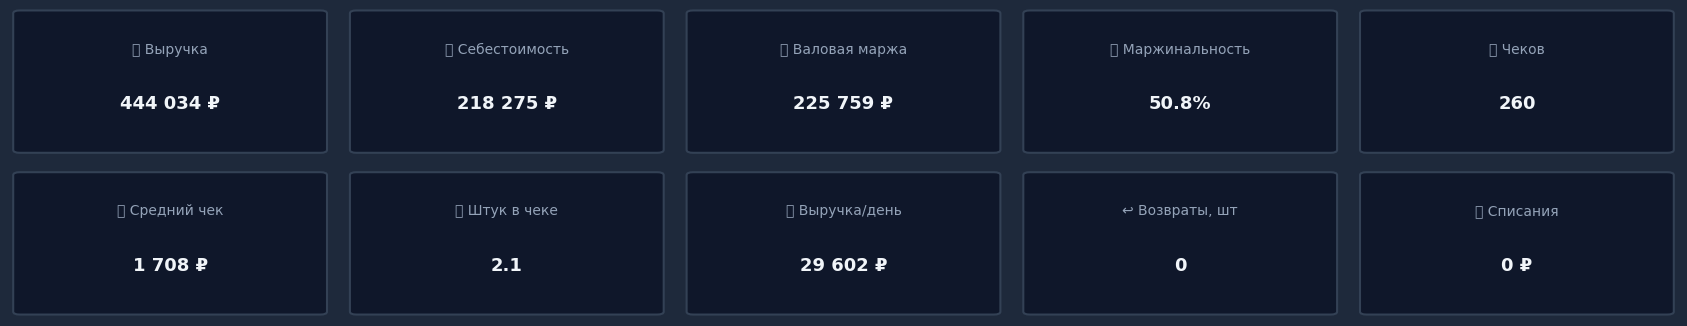

Списания: 0 ₽ = 0.0% от себестоимости продаж (Движение товаров)


In [7]:
total_rev     = df_s['Выручка'].sum()
total_cost    = df_s['Себестоимость'].sum()
total_margin  = total_rev - total_cost
margin_pct    = total_margin / total_rev * 100 if total_rev else np.nan
n_checks      = df_s['check_key'].nunique()
avg_check     = total_rev / n_checks if n_checks else np.nan
items_per_chk = len(df_s) / n_checks if n_checks else np.nan
days_span     = (df_s['Дата'].max().normalize() - df_s['Дата'].min().normalize()).days + 1
ret_qty       = df_s.loc[df_s['Возврат'], 'Кол-во'].abs().sum()

writeoff  = docs_f[docs_f['Это_списание']]
wo_sum    = writeoff['Расход (себест.)'].sum()
wo_source = 'Движение товаров'
if wo_sum == 0 and 'Списания_док' in extra:
    wo_sum    = float(extra['Списания_док']['Сумма'].sum())
    wo_source = 'файл «Списания»'

kpis = [
    ('💰 Выручка',           rub(total_rev)),
    ('📉 Себестоимость',     rub(total_cost)),
    ('🟢 Валовая маржа',     rub(total_margin)),
    ('📊 Маржинальность',    pct(margin_pct)),
    ('🧾 Чеков',             num_fmt(n_checks)),
    ('🎯 Средний чек',       rub(avg_check)),
    ('📦 Штук в чеке',       f'{items_per_chk:.1f}'),
    ('📈 Выручка/день',      rub(total_rev/days_span)),
    ('↩️ Возвраты, шт',      num_fmt(ret_qty)),
    ('🗑 Списания',          rub(wo_sum)),
]
fig, axes = plt.subplots(2, 5, figsize=(17, 3.4))
fig.patch.set_facecolor('#1E293B')
for ax, (t, v) in zip(axes.ravel(), kpis):
    ax.axis('off'); ax.set_facecolor('#1E293B')
    ax.add_patch(mpatches.FancyBboxPatch((0.03,0.03), 0.94,0.94,
        boxstyle='round,pad=0.02', linewidth=1.5,
        edgecolor='#334155', facecolor='#0F172A',
        transform=ax.transAxes))
    ax.text(.5,.70,t,ha='center',fontsize=10,color='#94A3B8',transform=ax.transAxes)
    ax.text(.5,.32,v,ha='center',fontsize=13,fontweight='bold',
            color='#F1F5F9',transform=ax.transAxes)
plt.tight_layout(); plt.show()

print(f'Списания: {rub(wo_sum)} = {wo_sum/total_cost*100 if total_cost else 0:.1f}% '
      f'от себестоимости продаж ({wo_source})')

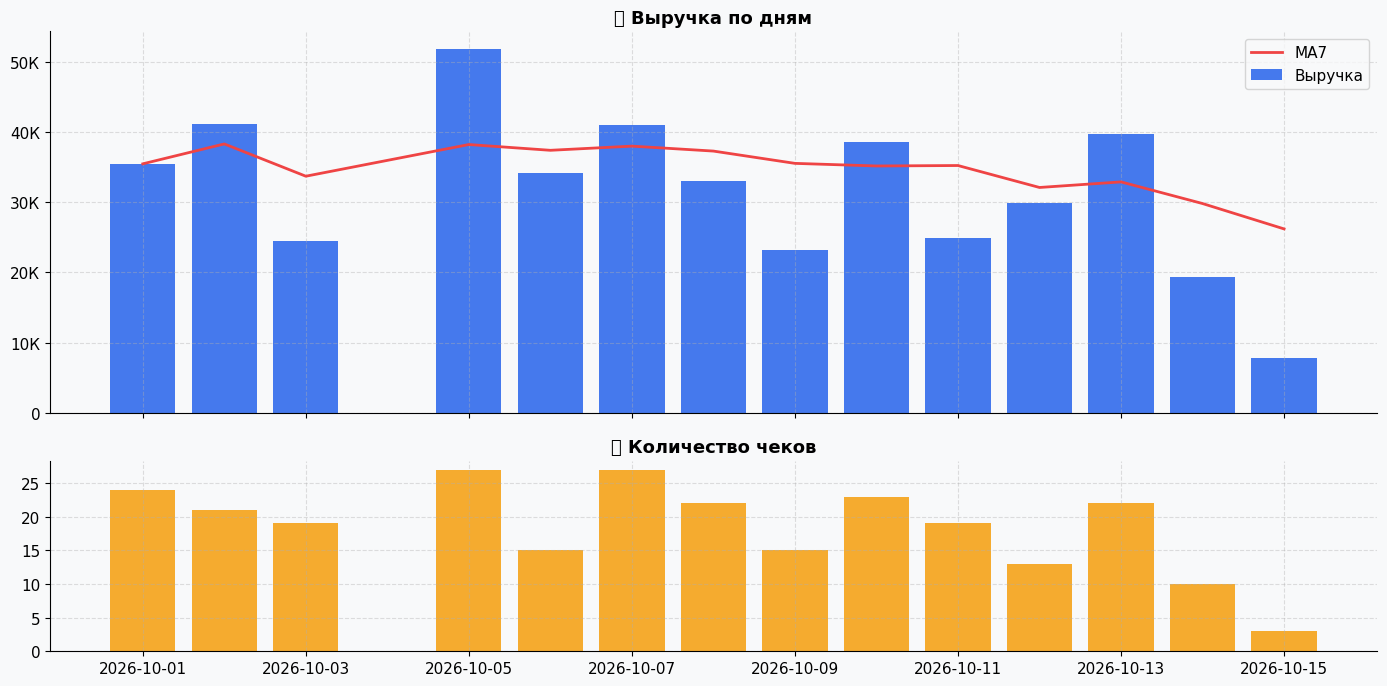

In [8]:
daily = df_s.groupby(df_s['Дата'].dt.normalize()).agg(
    Выручка=('Выручка','sum'), Маржа=('Маржа','sum'),
    Чеков=('check_key','nunique'), Штук=('Кол-во','sum')
).reset_index().rename(columns={'Дата':'День'})
daily['MA7'] = daily['Выручка'].rolling(7, min_periods=1).mean()

fig, axes = plt.subplots(2,1, figsize=(14,7), sharex=True,
                        gridspec_kw={'height_ratios':[2,1]})
axes[0].bar(daily['День'], daily['Выручка'], color=PALETTE[0], alpha=.85, label='Выручка')
axes[0].plot(daily['День'], daily['MA7'], color=PALETTE[3], lw=2, label='MA7')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
axes[0].set_title('💸 Выручка по дням'); axes[0].legend()
axes[1].bar(daily['День'], daily['Чеков'], color=PALETTE[2], alpha=.85)
axes[1].set_title('🧾 Количество чеков')
plt.tight_layout(); plt.show()

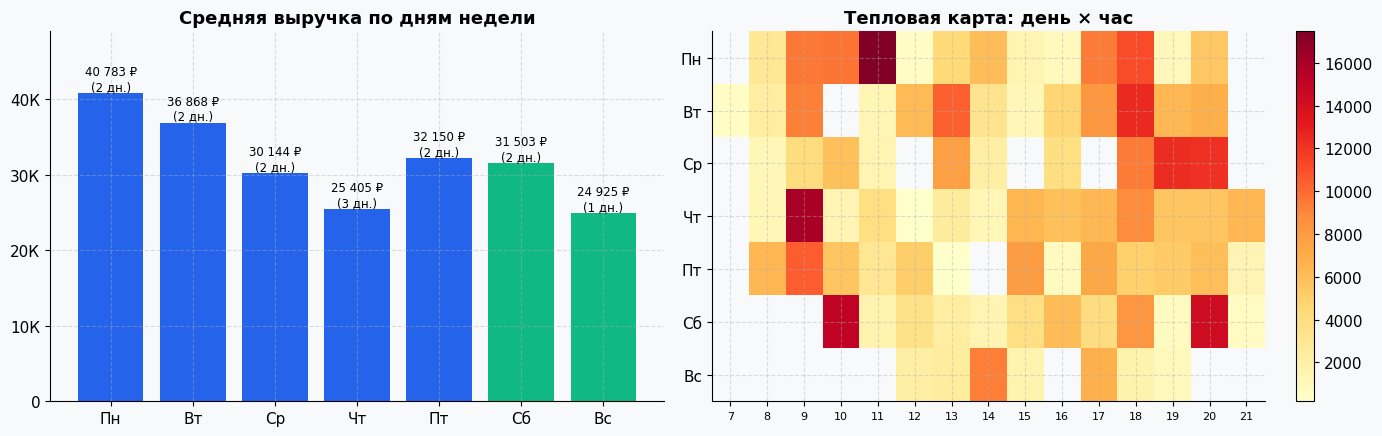

In [9]:
daily['День недели'] = daily['День'].dt.dayofweek
has = daily[daily['Чеков']>0]
dow = has.groupby('День недели').agg(Выручка=('Выручка','mean'),
                                     Чеков=('Чеков','mean'),
                                     Дней=('Выручка','size')).reindex(range(7)).fillna(0)

fig, axes = plt.subplots(1,2, figsize=(14,4.5))
cols = [PALETTE[1] if d in (5,6) else PALETTE[0] for d in dow.index]
bars = axes[0].bar(DAYS_RU, dow['Выручка'], color=cols)
for b,v,n in zip(bars, dow['Выручка'], dow['Дней']):
    axes[0].text(b.get_x()+b.get_width()/2, v, f'{rub(v)}\n({int(n)} дн.)',
                 ha='center', va='bottom', fontsize=8.5)
axes[0].set_title('Средняя выручка по дням недели')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
axes[0].set_ylim(0, dow['Выручка'].max()*1.2 if dow['Выручка'].max()>0 else 1)

hc = df_s[df_s['Час'].notna()].copy()
hc['hour'] = hc['Час'].astype(int); hc['wd'] = hc['Дата'].dt.dayofweek
pivot = hc.pivot_table(index='wd', columns='hour', values='Выручка', aggfunc='sum').reindex(range(7))
hm = axes[1].imshow(pivot.values, cmap='YlOrRd', aspect='auto')
axes[1].set_yticks(range(7)); axes[1].set_yticklabels(DAYS_RU)
axes[1].set_xticks(range(len(pivot.columns)))
axes[1].set_xticklabels([str(h) for h in pivot.columns], fontsize=8)
axes[1].set_title('Тепловая карта: день × час')
plt.colorbar(hm, ax=axes[1], fraction=.05)
plt.tight_layout(); plt.show()

In [10]:
def holidays_for_year(y):
    nov30 = pd.Timestamp(y,11,30)
    mothers = nov30 - pd.Timedelta(days=nov30.dayofweek)
    return {
        '14 февраля':  (pd.Timestamp(y,2,10),  pd.Timestamp(y,2,14)),
        '23 февраля':  (pd.Timestamp(y,2,21),  pd.Timestamp(y,2,23)),
        '8 марта':     (pd.Timestamp(y,3,2),   pd.Timestamp(y,3,8)),
        'День матери': (mothers - pd.Timedelta(days=4), mothers),
        '1 сентября':  (pd.Timestamp(y,8,30),  pd.Timestamp(y,9,1)),
        'Новый год':   (pd.Timestamp(y,12,26), pd.Timestamp(y,12,31)),
    }

yrs = sorted(set(df_s['Дата'].dt.year))
hol_ranges = {name:(a,b) for y in yrs for name,(a,b) in holidays_for_year(y).items()}
avg_day = daily.loc[daily['Чеков']>0, 'Выручка'].mean()
rows = []
for name,(a,b) in hol_ranges.items():
    win = daily[(daily['День']>=a) & (daily['День']<=b)]
    if len(win):
        rows.append({'Праздник': f'{name} {a.year}',
                     'Выручка': win['Выручка'].sum(),
                     'Дней': len(win),
                     'Выручка/день': win['Выручка'].sum()/len(win)})
hol = pd.DataFrame(rows)
if len(hol):
    hol = hol.sort_values('Выручка', ascending=False)
    fig, ax = plt.subplots(figsize=(11, max(3, .5*len(hol))))
    ax.barh(hol['Праздник'][::-1], hol['Выручка/день'][::-1], color=PALETTE[5])
    for i, (v, base) in enumerate(zip(hol['Выручка/день'][::-1],
                                       hol['Выручка/день'][::-1]/avg_day)):
        ax.text(v, i, f'  {rub(v)}  (×{base:.1f})', va='center', fontsize=9)
    ax.set_title(f'🎉 Средняя выручка в день праздника (обычный = {rub(avg_day)})')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
    ax.set_xlim(0, hol['Выручка/день'].max()*1.45)
    plt.tight_layout(); plt.show()
    display(hol.reset_index(drop=True))
else:
    print('ℹ️ В периоде нет праздничных окон.')

ℹ️ В периоде нет праздничных окон.


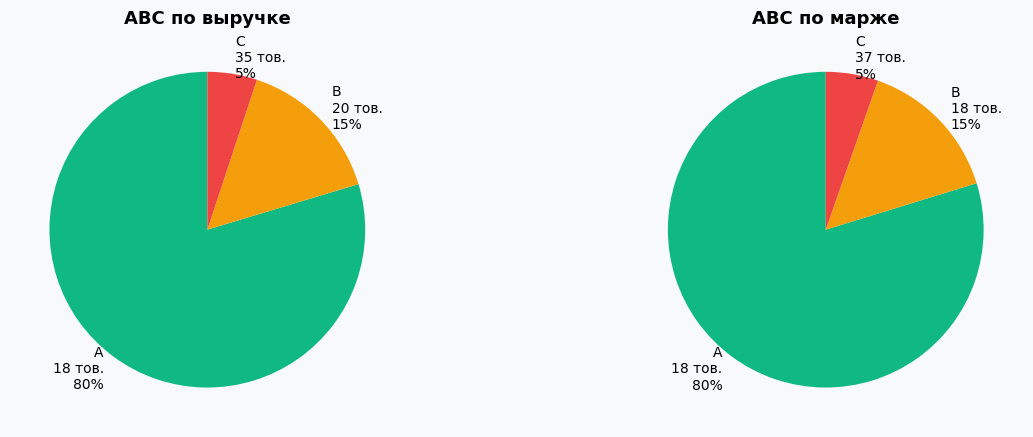

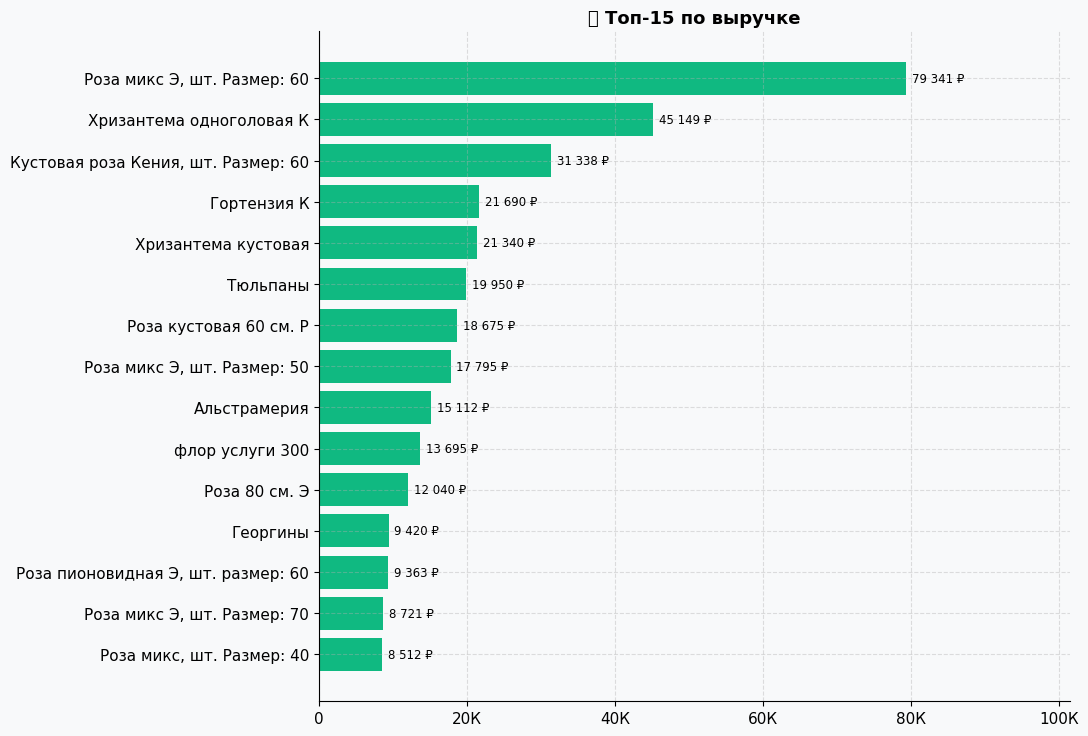

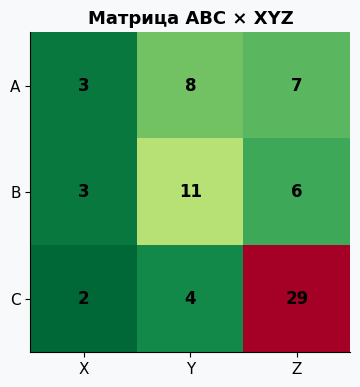

Класс XYZ,X,Y,Z
Класс,,,
A,3,8,7
B,3,11,6
C,2,4,29


In [11]:
def abc_table(data, value_col):
    t = data.groupby('Товар').agg(Выручка=('Выручка','sum'),
                                   Маржа=('Маржа','sum'),
                                   Продано=('Кол-во','sum'),
                                   Чеков=('check_key','nunique')).reset_index()
    t = t.sort_values(value_col, ascending=False).reset_index(drop=True)
    t['Доля %']   = t[value_col] / t[value_col].sum() * 100
    t['Накопл %'] = t['Доля %'].cumsum()
    t['Класс']    = np.where(t['Накопл %']<=80,'A',
                             np.where(t['Накопл %']<=95,'B','C'))
    return t

abc_rev  = abc_table(df_s, 'Выручка')
abc_marg = abc_table(df_s, 'Маржа')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, t, ttl in [(axes[0], abc_rev,  'ABC по выручке'),
                   (axes[1], abc_marg, 'ABC по марже')]:
    g = t.groupby('Класс').agg(Товаров=('Товар','size'), Доля=('Доля %','sum'))
    labels = [f'{k}\n{int(v["Товаров"])} тов.\n{v["Доля"]:.0f}%' for k, v in g.iterrows()]
    ax.pie(g['Доля'], labels=labels,
           colors=[ABC_COLORS[k] for k in g.index],
           startangle=90, textprops={'fontsize':10})
    ax.set_title(ttl)
plt.tight_layout(); plt.show()

top = abc_rev.head(TOP_N)
fig, ax = plt.subplots(figsize=(11, .4*len(top)+1.5))
barh_labels(ax, top['Товар'], top['Выручка'],
            [ABC_COLORS[c] for c in top['Класс']])
ax.invert_yaxis()
ax.set_title(f'🏆 Топ-{TOP_N} по выручке')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
plt.tight_layout(); plt.show()

wk = (df_s.assign(Неделя=df_s['Дата'] - pd.to_timedelta(df_s['Дата'].dt.dayofweek, unit='D'))
        .pivot_table(index='Товар', columns='Неделя', values='Кол-во', aggfunc='sum').fillna(0))
xyz = pd.DataFrame({'средн': wk.mean(axis=1),
                    'cv':   wk.std(axis=1) / wk.mean(axis=1) * 100})
xyz['Класс XYZ'] = np.where(xyz['cv']<=50,'X',
                            np.where(xyz['cv']<=100,'Y','Z'))
xyz.loc[xyz['средн']<=0, 'Класс XYZ'] = 'Z'
mat = abc_rev[['Товар','Класс']].merge(xyz[['Класс XYZ']],
                                        left_on='Товар', right_index=True, how='left')
mat['Класс XYZ'] = mat['Класс XYZ'].fillna('Z')
ct = pd.crosstab(mat['Класс'], mat['Класс XYZ'])

fig, ax = plt.subplots(figsize=(6,4))
ax.imshow(ct.values, cmap='RdYlGn_r')
ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns)
ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j,i,ct.values[i,j],ha='center',va='center',fontsize=12,fontweight='bold')
ax.set_title('Матрица ABC × XYZ'); ax.grid(False)
plt.tight_layout(); plt.show()
display(ct)

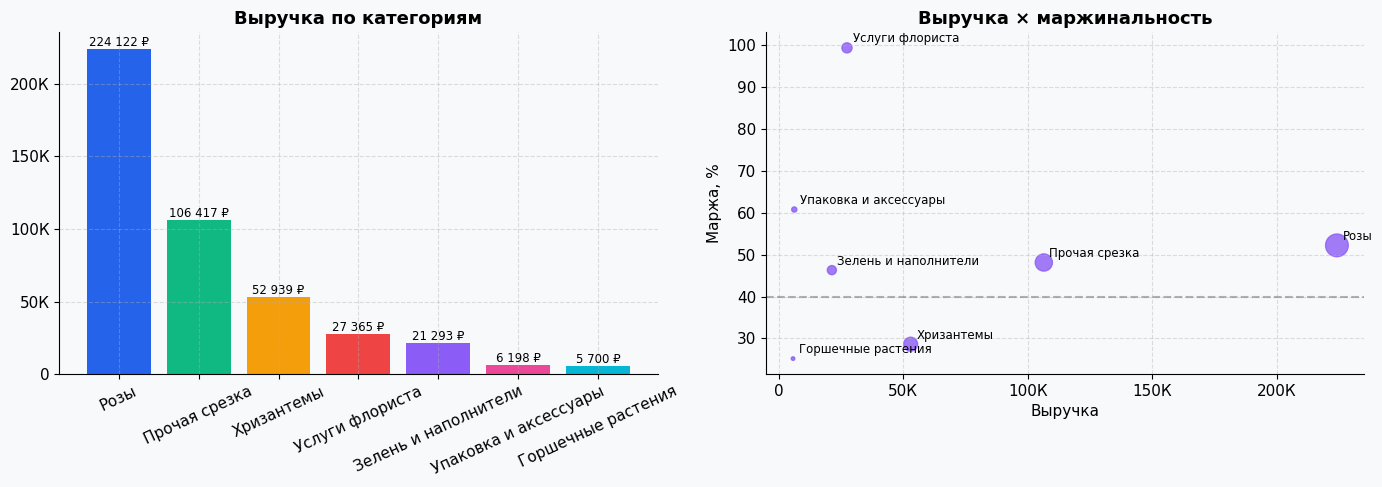

,Категория,Выручка,Маржа,Продано,Чеков,Маржа %
3,Розы,224122.18,117089.76,1101.0,136,52.243718
2,Прочая срезка,106416.93,51236.42,460.0,74,48.146869
6,Хризантемы,52939.24,15159.24,301.0,64,28.635167
5,Услуги флориста,27364.78,27205.78,159.0,80,99.418961
1,Зелень и наполнители,21293.02,9863.57,129.0,37,46.323020
4,Упаковка и аксессуары,6197.54,3768.20,42.0,26,60.801544
0,Горшечные растения,5700.00,1436.00,11.0,7,25.192982


In [12]:
cat = df_s.groupby('Категория').agg(
    Выручка=('Выручка','sum'), Маржа=('Маржа','sum'),
    Продано=('Кол-во','sum'), Чеков=('check_key','nunique')
).reset_index()
cat['Маржа %'] = cat['Маржа'] / cat['Выручка'] * 100
cat = cat.sort_values('Выручка', ascending=False)

fig, axes = plt.subplots(1,2, figsize=(14,5))
bars = axes[0].bar(cat['Категория'], cat['Выручка'], color=PALETTE[:len(cat)])
for b,v in zip(bars, cat['Выручка']):
    axes[0].text(b.get_x()+b.get_width()/2, v, rub(v), ha='center', va='bottom', fontsize=8.5)
axes[0].set_title('Выручка по категориям'); axes[0].tick_params(axis='x', rotation=25)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))

axes[1].scatter(cat['Выручка'], cat['Маржа %'],
                s=cat['Продано'].clip(20,800)/3, color=PALETTE[4], alpha=.8)
for _,r in cat.iterrows():
    axes[1].annotate(r['Категория'], (r['Выручка'], r['Маржа %']),
                     fontsize=8.5, xytext=(4,4), textcoords='offset points')
axes[1].axhline(MARGIN_TARGET, ls='--', color='gray', alpha=.6)
axes[1].set_xlabel('Выручка'); axes[1].set_ylabel('Маржа, %')
axes[1].set_title('Выручка × маржинальность')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
plt.tight_layout(); plt.show()
display(cat)

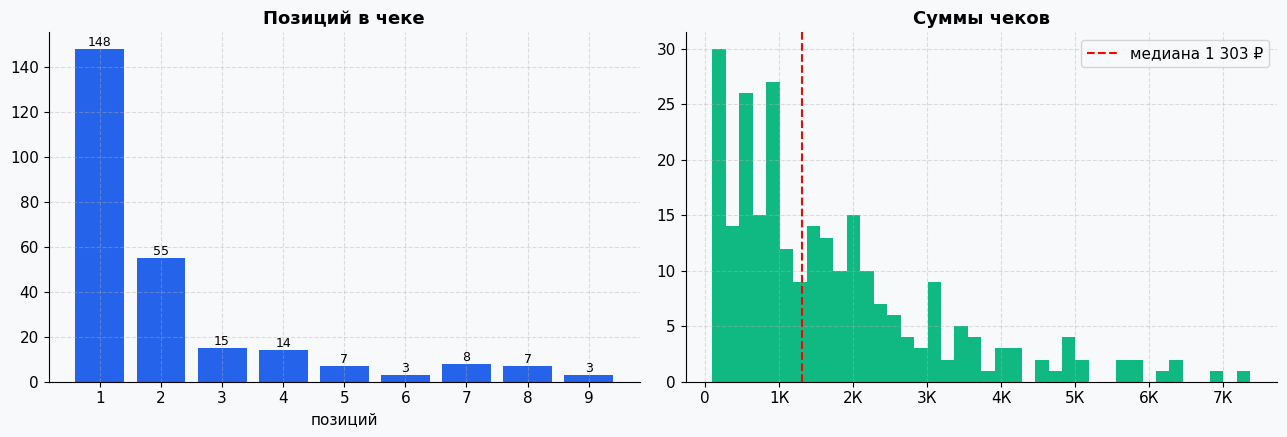

Пар: 8. Топ-10:


,Товар A,Товар B,Чеков с парой,Поддержка %,Lift,Конф. A→B,Конф. B→A
0,Оазис,Сумки средние,6,2.37,28.11,66.67,100.00
3,Вакс-флаур,Гортензия К,7,2.77,8.01,53.85,41.18
6,Оазис,Хризантема кустовая,6,2.37,5.44,66.67,19.35
1,Альстрамерия,Гортензия К,6,2.37,4.06,27.27,35.29
4,Вакс-флаур,Хризантема кустовая,6,2.37,3.77,46.15,19.35
2,Альстрамерия,Хризантема кустовая,9,3.56,3.34,40.91,29.03
5,Гортензия К,Хризантема кустовая,5,1.98,2.40,29.41,16.13
7,"Кустовая роза Кения, шт. Размер: 60",Хризантема кустовая,5,1.98,2.15,26.32,16.13


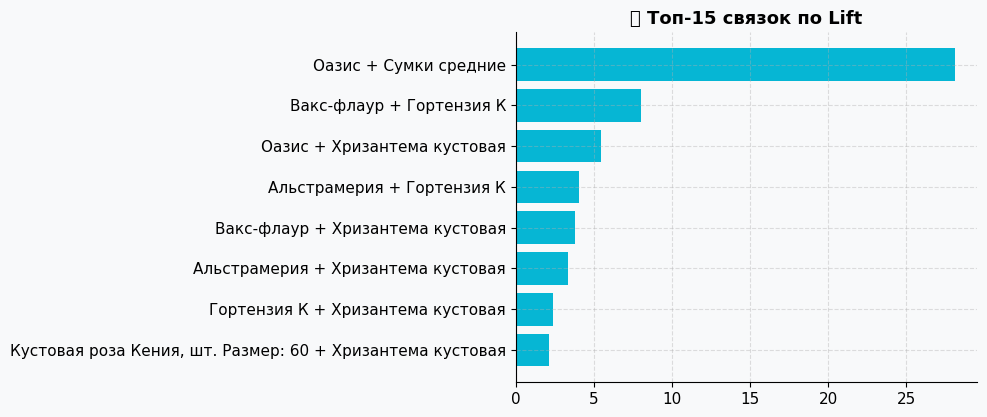

In [13]:
bk_src = df_s[~df_s['Категория'].isin(EXCLUDE_FROM_BASKET)]
chk = df_s.groupby('check_key').agg(Выручка=('Выручка','sum'),
                                     Позиций=('Товар','count'),
                                     Штук=('Кол-во','sum'))
fig, axes = plt.subplots(1,2, figsize=(13,4.5))
sz = chk['Позиций'].clip(upper=10).value_counts().sort_index()
axes[0].bar(sz.index.astype(str), sz.values, color=PALETTE[0])
axes[0].set_title('Позиций в чеке'); axes[0].set_xlabel('позиций')
for i,(x,y) in enumerate(zip(sz.index.astype(str), sz.values)):
    axes[0].text(i, y, int(y), ha='center', va='bottom', fontsize=9)
dist = chk['Выручка']
axes[1].hist(dist[dist>0], bins=40, color=PALETTE[1])
axes[1].axvline(dist.median(), color='red', ls='--', label=f'медиана {rub(dist.median())}')
axes[1].set_title('Суммы чеков'); axes[1].legend()
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
plt.tight_layout(); plt.show()

baskets = bk_src.groupby('check_key')['Товар'].apply(set)
n_b = len(baskets)
cnt = Counter(); pair_cnt = Counter()
for b in baskets:
    cnt.update(b)
    for p in combinations(sorted(b), 2): pair_cnt[p] += 1

rows=[]
for (a,b), c in pair_cnt.items():
    if c < MIN_PAIR_COUNT: continue
    sup  = c / n_b
    lift = c * n_b / (cnt[a] * cnt[b])
    if sup >= MIN_SUPPORT and lift > 1:
        rows.append({'Товар A':a,'Товар B':b,'Чеков с парой':c,
                     'Поддержка %':sup*100, 'Lift':lift,
                     'Конф. A→B':c/cnt[a]*100, 'Конф. B→A':c/cnt[b]*100})
mb = pd.DataFrame(rows).sort_values('Lift', ascending=False)

if len(mb):
    print(f'Пар: {len(mb)}. Топ-10:')
    display(mb.head(10).round(2))
    fig, ax = plt.subplots(figsize=(10, .35*min(15,len(mb))+1.5))
    t = mb.head(15)[::-1]
    ax.barh([f'{a} + {b}' for a,b in zip(t['Товар A'], t['Товар B'])],
            t['Lift'], color=PALETTE[6])
    ax.set_title('🧺 Топ-15 связок по Lift')
    plt.tight_layout(); plt.show()
else:
    print('ℹ️ Заметных пар нет.')

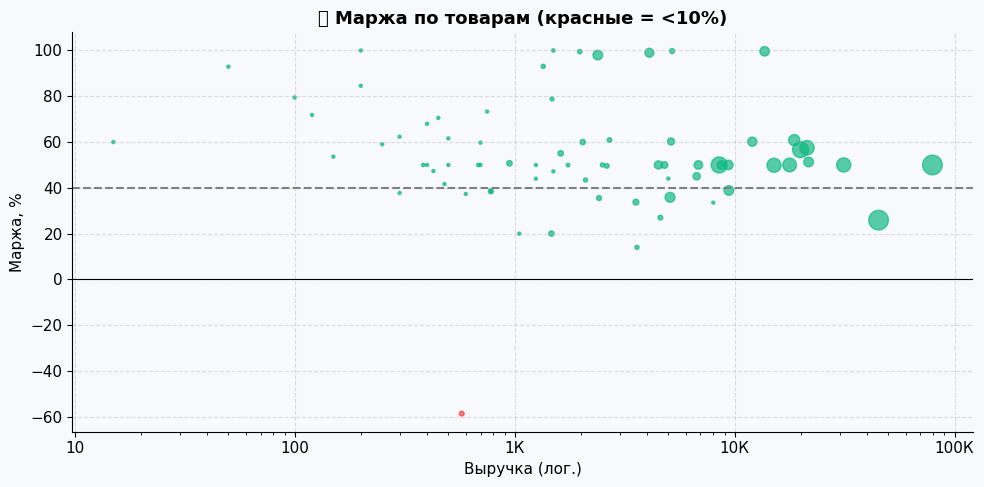

🚨 Маржа <10%: 1 товаров


,Товар,Выручка,Маржа,Маржа %,Продано
31,Оазис,575.04,-336.96,-58.597663,12.0


⚠️ Ходовые, но <40%: 8


,Товар,Выручка,Маржа %,Продано
65,Хризантема одноголовая К,45149.49,25.890636,239.0
9,Георгины,9420.00,38.853503,48.0
40,Протея люкс,8000.00,33.527000,4.0
53,Сантини,5089.80,35.871743,51.0
29,Лилия 5+,4599.96,26.955887,12.0
0,Алиум,3600.00,14.000000,9.0
55,Скимия,3560.04,33.764789,18.0
8,Гелиантус,2419.95,35.535858,13.0


In [14]:
pm = df_s[~df_s['Возврат']].groupby('Товар').agg(
    Выручка=('Выручка','sum'), Маржа=('Маржа','sum'),
    Продано=('Кол-во','sum'),
    Себестоимость=('Себестоимость','sum'),
    Средняя_цена=('Цена продажи','mean')
).reset_index()
pm['Маржа %']   = np.where(pm['Выручка']>0, pm['Маржа']/pm['Выручка']*100, np.nan)
pm['Наценка %'] = np.where(pm['Себестоимость']>0,
                            pm['Маржа']/pm['Себестоимость']*100, np.nan)

neg = pm[(pm['Маржа']<0)|(pm['Маржа %']<10)].sort_values('Маржа')
low = pm[(pm['Маржа %']<MARGIN_TARGET) &
         (pm['Выручка']>pm['Выручка'].quantile(.5))].sort_values('Выручка', ascending=False)

fig, ax = plt.subplots(figsize=(10,5))
samp = pm[pm['Выручка']>0].sample(min(400,(pm['Выручка']>0).sum()), random_state=1)
ax.scatter(samp['Выручка'], samp['Маржа %'],
           s=samp['Продано'].clip(5,200),
           c=np.where(samp['Маржа %']<10, PALETTE[3], PALETTE[1]), alpha=.7)
ax.axhline(MARGIN_TARGET, ls='--', color='gray'); ax.axhline(0, color='black', lw=.8)
ax.set_xscale('log')
ax.set_xlabel('Выручка (лог.)'); ax.set_ylabel('Маржа, %')
ax.set_title('💹 Маржа по товарам (красные = <10%)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
plt.tight_layout(); plt.show()

print(f'🚨 Маржа <10%: {len(neg)} товаров')
if len(neg): display(neg[['Товар','Выручка','Маржа','Маржа %','Продано']].head(10))
print(f'⚠️ Ходовые, но <{MARGIN_TARGET}%: {len(low)}')
if len(low): display(low[['Товар','Выручка','Маржа %','Продано']].head(10))

In [15]:
last_sale = df_s[~df_s['Возврат']].groupby('Товар')['Дата'].max()
st = stock.merge(last_sale.rename('Последняя продажа'),
                 left_on='Товар', right_index=True, how='left')
period_days_cnt = (_dmax - _dmin).days + 1
st['Никогда не продавался'] = st['Последняя продажа'].isna()
st['Дней без продаж'] = np.where(
    st['Последняя продажа'].isna(), period_days_cnt,
    (_dmax - st['Последняя продажа']).dt.days).astype(int)

dead = st[(st['Кон. остаток']>0) & (st['Дней без продаж']>=SLOW_DAYS)] \
        .sort_values('Остаток, ₽', ascending=False)
print(f'🧊 Залежалый: {len(dead)} поз. на {rub(dead["Остаток, ₽"].sum()) if len(dead) else "0 ₽"}')
if len(dead):
    display(dead[['Товар','Категория','Кон. остаток','Остаток, ₽',
                  'Дней без продаж','Никогда не продавался']].head(15))

win_start = _dmax - pd.Timedelta(days=COVER_LOOKBACK - 1)
win = df_s[(df_s['Дата'] >= win_start) & (~df_s['Возврат'])]
work_days = max(win['Дата'].dt.normalize().nunique(), 1)
speed = win.groupby('Товар')['Кол-во'].sum() / work_days

snr = df_s[~df_s['Возврат']].groupby('Товар').agg(
    К_сум=('Кол-во','sum'), С_сум=('Себестоимость','sum'))
snr['Себест_ед_продажи'] = np.where(snr['К_сум'] > 0,
                                     snr['С_сум']/snr['К_сум'], np.nan)
stock['Себест_ед_остаток'] = np.where(stock['Кон. остаток'] > 0,
                                       stock['Остаток, ₽']/stock['Кон. остаток'], np.nan)
unit_cost = stock[['Товар','Себест_ед_остаток']].copy()
unit_cost['Себест_ед_продажи'] = unit_cost['Товар'].map(snr['Себест_ед_продажи'])
unit_cost['Себест_ед'] = unit_cost['Себест_ед_продажи'].fillna(
    unit_cost['Себест_ед_остаток']).fillna(0)

plan = stock[['Товар','Категория','Кон. остаток']].copy()
plan['Шт/день'] = plan['Товар'].map(speed).fillna(0)
plan['Нужно']   = (plan['Шт/день'] * COVER_DAYS).round(0)
plan['Заказать, шт'] = (plan['Нужно'] - plan['Кон. остаток']).clip(lower=0).round(0)
plan['Себест. ед.'] = plan['Товар'].map(unit_cost.set_index('Товар')['Себест_ед']).fillna(0)
plan['Сумма закупки, ₽'] = plan['Заказать, шт'] * plan['Себест. ед.']
buy = plan[(plan['Заказать, шт'] > 0) &
           (~plan['Категория'].isin(EXCLUDE_FROM_BASKET))] \
        .sort_values('Шт/день', ascending=False)

print(f'🛒 К заказу на {COVER_DAYS} дн.: {len(buy)} поз. на ≈ {rub(buy["Сумма закупки, ₽"].sum())}')
display(buy[['Товар','Категория','Шт/день','Кон. остаток',
             'Заказать, шт','Сумма закупки, ₽']].head(20))

🧊 Залежалый: 0 поз. на 0 ₽
🛒 К заказу на 4 дн.: 16 поз. на ≈ 17 650 ₽


,Товар,Категория,Шт/день,Кон. остаток,"Заказать, шт","Сумма закупки, ₽"
442,Хризантема одноголовая К,Хризантемы,17.071429,43.0,25.0,3500.000000
225,"Кустовая роза Кения, шт. Размер: 60",Розы,7.428571,0.0,30.0,4519.903846
335,"Роза микс Э, шт. Размер: 50",Розы,6.928571,0.0,28.0,2568.321649
345,"Роза пионовидная Э, шт. размер: 60",Розы,3.357143,0.0,13.0,1294.882979
337,"Роза микс Э, шт. Размер: 70",Розы,2.785714,0.0,11.0,1229.918462
339,"Роза микс, шт. Размер: 50",Розы,2.500000,0.0,10.0,643.714286
98,Гипсофила,Зелень и наполнители,1.857143,0.0,7.0,550.092308
224,"Кустовая роза Кения, шт. Размер: 50",Розы,0.642857,0.0,3.0,418.133333
13,Алиум,Горшечные растения,0.642857,0.0,3.0,1032.000000
388,Сумки средние,Упаковка и аксессуары,0.571429,1.0,1.0,39.200000


ℹ️ Истории < 3 недель — backtest пропускаем.


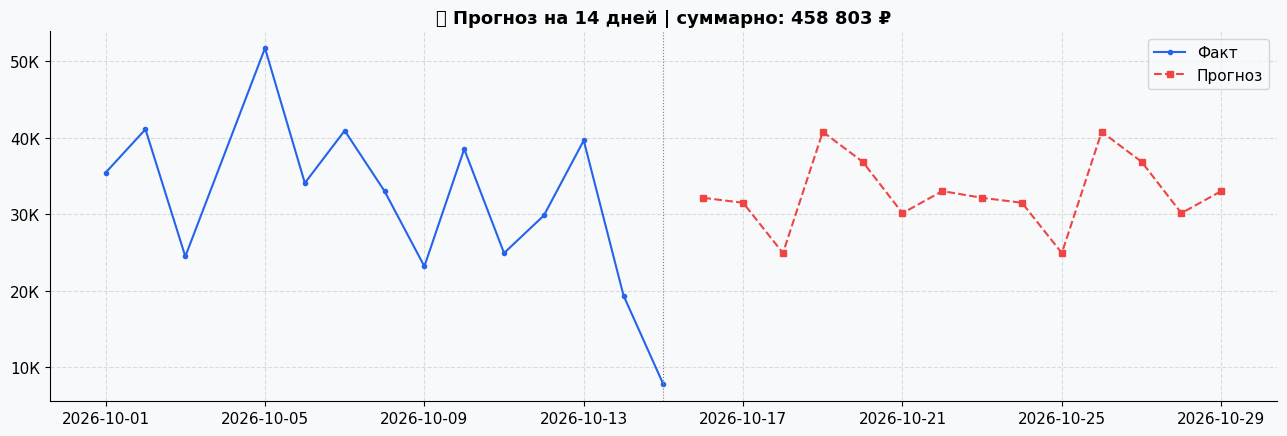

In [16]:
series = daily.set_index('День')['Выручка'].asfreq('D')
hist   = series.dropna()

def predict_dow(h, target, weeks=8):
    same = h[(h.index.dayofweek==target.dayofweek) &
             (h.index >= target - pd.Timedelta(weeks=weeks))]
    if len(same)==0:
        same = h[h.index.dayofweek==target.dayofweek]
    return same.median() if len(same) else h.mean()

bt_dates = hist.index[-14:] if len(hist) >= 21 else hist.index[:0]
err = {}
if len(bt_dates) == 0:
    print('ℹ️ Истории < 3 недель — backtest пропускаем.')
else:
    for name, fn in [
        ('по дню недели',     lambda h,t: predict_dow(h,t)),
        ('среднее за 28 дн.', lambda h,t: h.tail(28).mean()),
        ('наивный (вчера)',   lambda h,t: h.iloc[-1]),
    ]:
        preds = [fn(hist[hist.index<d], d) for d in bt_dates]
        err[name] = np.mean(np.abs(np.array(preds) - hist.loc[bt_dates].values))
    best = min(err, key=err.get)
    print('📉 MAE прогноза:', {k: rub(v) for k,v in err.items()}, f'→ лучший: {best}')

future = pd.date_range(series.index.max() + pd.Timedelta(days=1),
                       periods=FORECAST_DAYS, freq='D')
fc = pd.Series([predict_dow(hist, d) for d in future], index=future)
fig, ax = plt.subplots(figsize=(13,4.5))
ax.plot(hist.index, hist.values, marker='o', ms=3, color=PALETTE[0], label='Факт')
ax.plot(fc.index, fc.values, marker='s', ms=5, color=PALETTE[3], ls='--', label='Прогноз')
ax.axvline(series.index.max(), color='gray', lw=.8, ls=':')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis)); ax.legend()
ax.set_title(f'🔮 Прогноз на {FORECAST_DAYS} дней | суммарно: {rub(fc.sum())}')
plt.tight_layout(); plt.show()

In [17]:
alerts = []

# 18.1 Невязки
for _, r in bad.sort_values('Невязка, шт').iterrows():
    alerts.append({'Проверка':'18.1 Невязка остатков',
                   'Объект': r['Товар'],
                   'Метрика': f'{r["Невязка, шт"]:+.0f} шт',
                   'Комментарий': 'кража или незадокументированное движение'})

# 18.2 Пики списаний
wo_daily = pd.Series(dtype=float)
if len(writeoff):
    wo_daily = writeoff.groupby(writeoff['Дата'].dt.normalize())['Расход (себест.)'].sum()
elif 'Списания_док' in extra:
    wd = extra['Списания_док']
    wo_daily = wd.groupby(wd['Дата'].dt.normalize())['Сумма'].sum()

print(f'🗑 Списания: {wo_source}, всего {rub(wo_sum)}, дней {len(wo_daily)}')
if len(wo_daily):
    fig, ax = plt.subplots(figsize=(12,3.6))
    med0 = wo_daily.median()
    cols = [PALETTE[3] if v > med0*WRITEOFF_SPIKE_KOEF else PALETTE[0] for v in wo_daily]
    ax.bar(wo_daily.index, wo_daily.values, color=cols)
    ax.axhline(med0*WRITEOFF_SPIKE_KOEF, ls='--', color=PALETTE[3], label=f'×{WRITEOFF_SPIKE_KOEF}')
    ax.set_title('Ежедневные списания (красные — аномальные)'); ax.legend()
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_rub_axis))
    plt.tight_layout(); plt.show()

if len(wo_daily) >= 5:
    med = wo_daily.median(); mad = (wo_daily - med).abs().median()
    spike_days = wo_daily[wo_daily > med*WRITEOFF_SPIKE_KOEF + 3*mad*1.4826]
    for d, v in spike_days.items():
        alerts.append({'Проверка':'18.2 Пик списаний',
                       'Объект': f'{d:%d.%m.%Y}', 'Метрика': rub(v),
                       'Комментарий': f'×{v/med:.1f} от медианы ({rub(med)})'})

# 18.3 Профиль списаний
if 'Списания_док' in extra:
    wd = extra['Списания_док']
    print('\n📋 Причины списаний:')
    display(wd.groupby('Причина', dropna=False)['Сумма']
              .agg(['count','sum']).sort_values('sum', ascending=False))
    bp = wd.groupby('Кто оформил')['Сумма'].agg(['count','sum']).sort_values('sum', ascending=False)
    if len(bp) > 1:
        print('\n👤 Кто оформляет списания:')
        display(bp)
    late = wd[wd['Дата'].dt.hour >= 20]
    if len(late):
        print(f'\n🌙 Списаний после 20:00: {len(late)} на {rub(late["Сумма"].sum())} — '
              f'ночные «акты порчи» — след прикрытия хищения (#7).')

# 18.4 Возвраты
rets = df_s[df_s['Возврат']].copy()
if len(rets):
    ret_daily = rets.groupby(rets['Дата'].dt.normalize()).size()
    checks_daily = df_s.groupby(df_s['Дата'].dt.normalize())['check_key'].nunique()
    rate = (ret_daily / checks_daily * 100).fillna(0)
    late = rets[rets['Час'].notna() & (rets['Час'] >= 18)]
    print(f'↩️ Возвратов: {len(rets)} поз. ({rate.mean():.1f}% чеков). После 18:00: {len(late)}')
    if rate.mean() > RETURN_RATE_ALERT:
        alerts.append({'Проверка':'18.4 Возвраты', 'Объект':'магазин',
                       'Метрика': f'{rate.mean():.1f}%',
                       'Комментарий':'высокая доля возвратов'})
    for d, v in rate.sort_values(ascending=False).head(3).items():
        alerts.append({'Проверка':'18.4 Пик возвратов',
                       'Объект': f'{d:%d.%m.%Y}', 'Метрика': f'{v:.0f}%',
                       'Комментарий':'всплеск возвратов'})
else:
    print('↩️ Возвратов нет.')

# 18.5 Сверка Движение ↔ Касса
if cash is not None and len(cash):
    ccol = next((c for c in cash.columns
                 if 'итого' in c.lower() or 'выручка' in c.lower()), None)
    if ccol:
        rc = cash[['Дата', ccol]].copy()
        rc['ccol'] = to_num(rc[ccol])
        mv_daily = df_s.groupby(df_s['Дата'].dt.normalize())['Выручка'].sum()
        cmp = pd.DataFrame({'Касса': rc.set_index('Дата')['ccol'],
                            'БизнесРу': mv_daily}).dropna()
        cmp['Разница %'] = np.where(cmp['Касса']>0,
                                     (cmp['БизнесРу']-cmp['Касса'])/cmp['Касса']*100, np.nan)
        big = cmp[cmp['Разница %'].abs() > 5]
        print(f'🧮 Сверка vs Касса: дней {len(cmp)}, расхождений >5%: {len(big)}')
        for d, r in big.head(10).iterrows():
            alerts.append({'Проверка':'18.5 Движение↔Касса',
                           'Объект': f'{d:%d.%m.%Y}',
                           'Метрика': f'{r["Разница %"]:+.1f}%',
                           'Комментарий':'непробитая продажа (#2)'})

# 18.6 Цены ниже прайса
price_ref = df_s.groupby('Товар')['Цена продажи'].median()
tmp = df_s[~df_s['Возврат']].copy()
tmp['откл'] = (tmp['Цена продажи'] - tmp['Товар'].map(price_ref)) / \
              tmp['Товар'].map(price_ref).replace(0, np.nan) * 100
disc_days = tmp[tmp['откл'] < -15].groupby(tmp['Дата'].dt.normalize()).size()
if len(disc_days):
    print(f'💸 Позиций с ценой >15% ниже медианной: {int((tmp["откл"]<-15).sum())}')

# 18.7 Пересортица
mv_by_day_item = docs_f.groupby([docs_f['Дата'].dt.normalize(),'Товар'])['Расход, шт'].sum()
cross = 0
for d, grp in mv_by_day_item.groupby(level=0):
    if (grp <= -5).any() and (grp >= 5).any():
        cross += 1
if cross:
    print(f'🔄 Дней с «+» и «−» крупных партий: {cross}')

alert_df = pd.DataFrame(alerts)
print('\n' + '='*60)
print(f'🚨 ИТОГО сигналов к проверке: {len(alert_df)}')
print('='*60)
if len(alert_df):
    display(alert_df)
else:
    print('✅ Явных аномалий не найдено.')

🗑 Списания: Движение товаров, всего 0 ₽, дней 0
↩️ Возвратов нет.
🧮 Сверка vs Касса: дней 14, расхождений >5%: 3
💸 Позиций с ценой >15% ниже медианной: 4

🚨 ИТОГО сигналов к проверке: 3


,Проверка,Объект,Метрика,Комментарий
0,18.5 Движение↔Касса,07.10.2026,+6.6%,непробитая продажа (#2)
1,18.5 Движение↔Касса,11.10.2026,-7.3%,непробитая продажа (#2)
2,18.5 Движение↔Касса,14.10.2026,-6.1%,непробитая продажа (#2)


In [18]:
# ─── Резюме ───────────────────────────────────────────────────────────
top3 = abc_rev.head(3)['Товар'].tolist()
share_top = abc_rev[abc_rev['Класс']=='A']
worst_wo_day = wo_daily.idxmax() if len(wo_daily) else None
worst_str = f'{worst_wo_day:%d.%m} ({rub(wo_daily.max())})' if len(wo_daily) else 'нет'

print(f'''
🧾 РЕЗЮМЕ ЗА ПЕРИОД {_dmin:%d.%m} — {_dmax:%d.%m}
──────────────────────────────────────────────
• Выручка {rub(total_rev)}, валовая маржа {rub(total_margin)} ({pct(margin_pct)}; цель {MARGIN_TARGET}%).
• Чеков {num_fmt(n_checks)}, средний чек {rub(avg_check)}, в чеке {items_per_chk:.1f} поз.
• Класс A: {len(share_top)} товаров дают 80% выручки. Топ-3: {", ".join(top3)}.
• Списания: {rub(wo_sum)} ({wo_sum/total_cost*100 if total_cost else 0:.1f}% от себест.). Крупнейший: {worst_str}.
• Залежалый товар: {len(dead)} поз. на {rub(dead["Остаток, ₽"].sum()) if len(dead) else "0 ₽"}.
• К заказу на {COVER_DAYS} дн.: {len(buy)} поз. (~{rub(buy["Сумма закупки, ₽"].sum())}).
• Сигналов детектора: {len(alert_df)}.
──────────────────────────────────────────────
''')

# ─── Экспорт в Excel ──────────────────────────────────────────────────
if not EXPORT_XLSX:
    print('Выгрузка отключена.')
else:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    out = os.path.join(OUTPUT_DIR, 'Отчет_розница_цветы.xlsx')
    sheets = {
        'KPI':            pd.DataFrame([{'показатель':k,'значение':v} for k,v in kpis]),
        'Динамика_день':  daily,
        'ABC_выручка':    abc_rev,
        'ABC_маржа':      abc_marg,
        'Категории':      cat,
        'Товары_маржа':   pm.sort_values('Выручка', ascending=False),
        'MarketBasket':   mb if len(mb) else pd.DataFrame(),
        'Остатки':        stock,
        'Залежалый':      dead,
        'План_закупки':   buy,
        'Списания_дни':   wo_daily.rename('Сумма').reset_index() if len(wo_daily) else pd.DataFrame(),
        'Алерты':         alert_df,
        'Прогноз':        fc.rename('Прогноз').reset_index().rename(columns={'index':'Дата'}),
        'Чеки_позиции':   df_s,
    }
    with pd.ExcelWriter(out, engine='openpyxl') as xw:
        for name, d in sheets.items():
            (d if isinstance(d, pd.DataFrame) else pd.DataFrame()) \
                .to_excel(xw, sheet_name=name[:31], index=False)
    print(f'💾 Сохранено: {out}')


🧾 РЕЗЮМЕ ЗА ПЕРИОД 01.10 — 15.10
──────────────────────────────────────────────
• Выручка 444 034 ₽, валовая маржа 225 759 ₽ (50.8%; цель 40%).
• Чеков 260, средний чек 1 708 ₽, в чеке 2.1 поз.
• Класс A: 18 товаров дают 80% выручки. Топ-3: Роза микс Э, шт. Размер: 60, Хризантема одноголовая К, Кустовая роза Кения, шт. Размер: 60.
• Списания: 0 ₽ (0.0% от себест.). Крупнейший: нет.
• Залежалый товар: 0 поз. на 0 ₽.
• К заказу на 4 дн.: 16 поз. (~17 650 ₽).
• Сигналов детектора: 3.
──────────────────────────────────────────────

💾 Сохранено: output\Отчет_розница_цветы.xlsx
